<a href="https://colab.research.google.com/github/molliekkutlwano-prog/Books-dataset--CODEALPHA-/blob/main/K_M_G%2C_Books_data_set_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TASK 1 WEB SCRAPING

In [1]:
from pathlib import Path
import re
import time
from bs4 import BeautifulSoup
import numpy as np
import pandas as pd
import requests

RATING_MAP = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5,
}

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/124.0.0.0 Safari/537.36"
    )
}


def scrape_books(max_pages: int = 3, delay_sec: float = 0.5) -> pd.DataFrame:
    """Scrapes book listings across catalog pages on books.toscrape.com."""
    base_url = "http://books.toscrape.com/"
    records = []

    for page in range(1, max_pages + 1):
        page_url = (
            base_url
            if page == 1
            else f"{base_url}catalogue/page-{page}.html"
        )
        try:
            response = requests.get(page_url, headers=HEADERS, timeout=10)
            response.raise_for_status()
        except requests.RequestException as exc:
            print(f"[Warning] Could not fetch {page_url}: {exc}")
            break

        soup = BeautifulSoup(response.text, "html.parser")
        items = soup.select("article.product_pod")
        if not items:
            break

        for item in items:
            title_el = item.select_one("h3 a")
            price_el = item.select_one("p.price_color")
            avail_el = item.select_one("p.instock.availability")
            rating_el = item.select_one("p.star-rating")

            title = (
                title_el.get("title", "").strip()
                if title_el and title_el.get("title")
                else "Unknown Title"
            )

            raw_price = price_el.get_text(strip=True) if price_el else ""
            price_match = re.search(r"(\d+\.\d+)", raw_price)
            price_gbp = float(price_match.group(1)) if price_match else np.nan

            availability = (
                avail_el.get_text(" ", strip=True) if avail_el else "Unknown"
            )
            in_stock = "in stock" in availability.lower()

            rating_stars = np.nan
            if rating_el:
                for cls in rating_el.get("class", []):
                    if cls in RATING_MAP:
                        rating_stars = RATING_MAP[cls]
                        break

            records.append({
                "page": page,
                "title": title,
                "price_gbp": price_gbp,
                "in_stock": in_stock,
                "availability_raw": availability,
                "rating_stars": rating_stars,
            })

        time.sleep(delay_sec)

    return pd.DataFrame(records)


def main() -> None:
    output_dir = Path("outputs")
    output_dir.mkdir(exist_ok=True)

    df = scrape_books(max_pages=3, delay_sec=0.5)

    if df.empty:
        print(
            "[Fallback] No live records fetched; generating local sample records."
        )
        df = pd.DataFrame({
            "page": [1, 1, 1, 1],
            "title": [
                "A Light in the Attic",
                "Tipping the Velvet",
                "Soumission",
                "Sharp Objects",
            ],
            "price_gbp": [51.77, 53.74, 50.10, 47.82],
            "in_stock": [True, True, True, True],
            "availability_raw": ["In stock"] * 4,
            "rating_stars": [3, 1, 1, 4],
        })

    csv_path = output_dir / "task1_books_dataset.csv"
    df.to_csv(csv_path, index=False)

    print("=== TASK 1 SCRAPING SUMMARY ===")
    print(f"Total rows scraped: {len(df)}")
    print(f"Missing values per column:\n{df.isnull().sum().to_string()}")
    print(f"\nData types:\n{df.dtypes.to_string()}")
    print(
        f"\nPrice range (GBP): {df['price_gbp'].min():.2f} - {df['price_gbp'].max():.2f}"
    )
    print(f"Average rating: {df['rating_stars'].mean():.2f} stars")
    print(f"\nSaved dataset to: {csv_path.resolve()}")
    print("\nFirst 5 rows:")
    print(df.head().to_string(index=False))


if __name__ == "__main__":
    main()

=== TASK 1 SCRAPING SUMMARY ===
Total rows scraped: 60
Missing values per column:
page                0
title               0
price_gbp           0
in_stock            0
availability_raw    0
rating_stars        0

Data types:
page                  int64
title                object
price_gbp           float64
in_stock               bool
availability_raw     object
rating_stars          int64

Price range (GBP): 12.84 - 57.31
Average rating: 3.00 stars

Saved dataset to: /content/outputs/task1_books_dataset.csv

First 5 rows:
 page                                 title  price_gbp  in_stock availability_raw  rating_stars
    1                  A Light in the Attic      51.77      True         In stock             3
    1                    Tipping the Velvet      53.74      True         In stock             1
    1                            Soumission      50.10      True         In stock             1
    1                         Sharp Objects      47.82      True         In stock    

TASK 2: EXPLORATORY DATA ANALYSIS

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd


def main() -> None:
    # Load Task 1 output (checks /content/outputs first, then current directory)
    candidate_paths = [
        Path("/content/outputs/task1_books_dataset.csv"),
        Path("outputs/task1_books_dataset.csv"),
        Path("task1_books_dataset.csv"),
    ]
    csv_path = next((p for p in candidate_paths if p.exists()), None)
    if csv_path is None:
        raise FileNotFoundError(
            "Could not find task1_books_dataset.csv. Run Task 1 first or upload the CSV."
        )

    df = pd.read_csv(csv_path)

    print("=== 1. PRE-ANALYSIS QUESTIONS ===")
    print(
        "1. How are book prices distributed across the 60 scraped titles, and are there extreme outliers?"
    )
    print(
        "2. How are star ratings (1 to 5) distributed across the catalog pages?"
    )
    print(
        "3. Do higher-rated books cost more on average than lower-rated books?"
    )

    print("\n=== 2. DATASET STRUCTURE & DATA TYPES ===")
    print(f"Source file: {csv_path}")
    print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
    print(df.dtypes.to_string())

    print("\n=== 3. DATA QUALITY & HYGIENE AUDIT ===")
    missing_df = pd.DataFrame({
        "missing_count": df.isnull().sum(),
        "missing_pct": (df.isnull().mean() * 100).round(2),
    })
    print(missing_df.to_string())
    print(f"Exact duplicate rows: {df.duplicated().sum()}")
    print(f"Duplicate book titles: {df['title'].duplicated().sum()}")

    # Feature engineering for EDA
    df["price_tier"] = pd.cut(
        df["price_gbp"],
        bins=[0, 25, 45, np.inf],
        labels=["Budget (<=£25)", "Mid-Range (£25-£45)", "Premium (>£45)"],
    )
    df["title_word_count"] = df["title"].astype(str).str.split().str.len()

    print("\n=== 4. SUMMARY STATISTICS & IQR OUTLIER CHECK ===")
    print(df[["price_gbp", "rating_stars", "title_word_count"]].describe().round(2).to_string())

    q1 = df["price_gbp"].quantile(0.25)
    q3 = df["price_gbp"].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    outliers = df[
        (df["price_gbp"] < lower_fence) | (df["price_gbp"] > upper_fence)
    ]
    print(
        f"\nPrice IQR Check -> Q1: £{q1:.2f} | Q3: £{q3:.2f} | IQR: £{iqr:.2f}"
    )
    print(f"Fences: [£{lower_fence:.2f}, £{upper_fence:.2f}] | Outliers detected: {len(outliers)}")

    print("\n=== 5. SEGMENT ANALYSIS: PRICE BY STAR RATING ===")
    rating_summary = (
        df.groupby("rating_stars", observed=False)
        .agg(
            book_count=("title", "count"),
            mean_price_gbp=("price_gbp", "mean"),
            median_price_gbp=("price_gbp", "median"),
            min_price_gbp=("price_gbp", "min"),
            max_price_gbp=("price_gbp", "max"),
        )
        .round(2)
    )
    print(rating_summary.to_string())

    print("\n=== 6. PRICE TIER & PAGE BREAKDOWN ===")
    print(df["price_tier"].value_counts().to_string())

    corr = df["rating_stars"].corr(df["price_gbp"])
    print(f"\nCorrelation (rating_stars vs. price_gbp): r = {corr:.3f}")

    # Save enriched EDA dataset
    out_dir = Path("outputs")
    out_dir.mkdir(exist_ok=True)
    enriched_path = out_dir / "task2_eda_books_enriched.csv"
    df.to_csv(enriched_path, index=False)
    print(f"\nSaved enriched EDA dataset to: {enriched_path.resolve()}")


if __name__ == "__main__":
    main()

=== 1. PRE-ANALYSIS QUESTIONS ===
1. How are book prices distributed across the 60 scraped titles, and are there extreme outliers?
2. How are star ratings (1 to 5) distributed across the catalog pages?
3. Do higher-rated books cost more on average than lower-rated books?

=== 2. DATASET STRUCTURE & DATA TYPES ===
Source file: /content/outputs/task1_books_dataset.csv
Shape: 60 rows x 6 columns
page                  int64
title                object
price_gbp           float64
in_stock               bool
availability_raw     object
rating_stars          int64

=== 3. DATA QUALITY & HYGIENE AUDIT ===
                  missing_count  missing_pct
page                          0          0.0
title                         0          0.0
price_gbp                     0          0.0
in_stock                      0          0.0
availability_raw              0          0.0
rating_stars                  0          0.0
Exact duplicate rows: 0
Duplicate book titles: 0

=== 4. SUMMARY STATISTICS & IQ

TASK4: SENTIMENTAL ANALYSIS

=== TASK 4: SENTIMENT ANALYSIS SUMMARY ===
Total reviews analyzed: 12
Missing values: 0
Average polarity score: 0.50

=== SENTIMENT DISTRIBUTION ===
           count  percentage
sentiment                   
Positive       6        50.0
Negative       4        33.3
Neutral        2        16.7

=== LABELED REVIEWS ===
 review_id                            book_title  polarity_score sentiment
         1 Sapiens: A Brief History of Humankind               4  Positive
         2                    Tipping the Velvet              -2  Negative
         3                  A Light in the Attic               3  Positive
         4                            Soumission              -3  Negative
         5                         Sharp Objects               2  Positive
         6                           In Her Wake               0   Neutral
         7                       The Black Maria              -2  Negative
         8                           Set Me Free               1  Positive
      

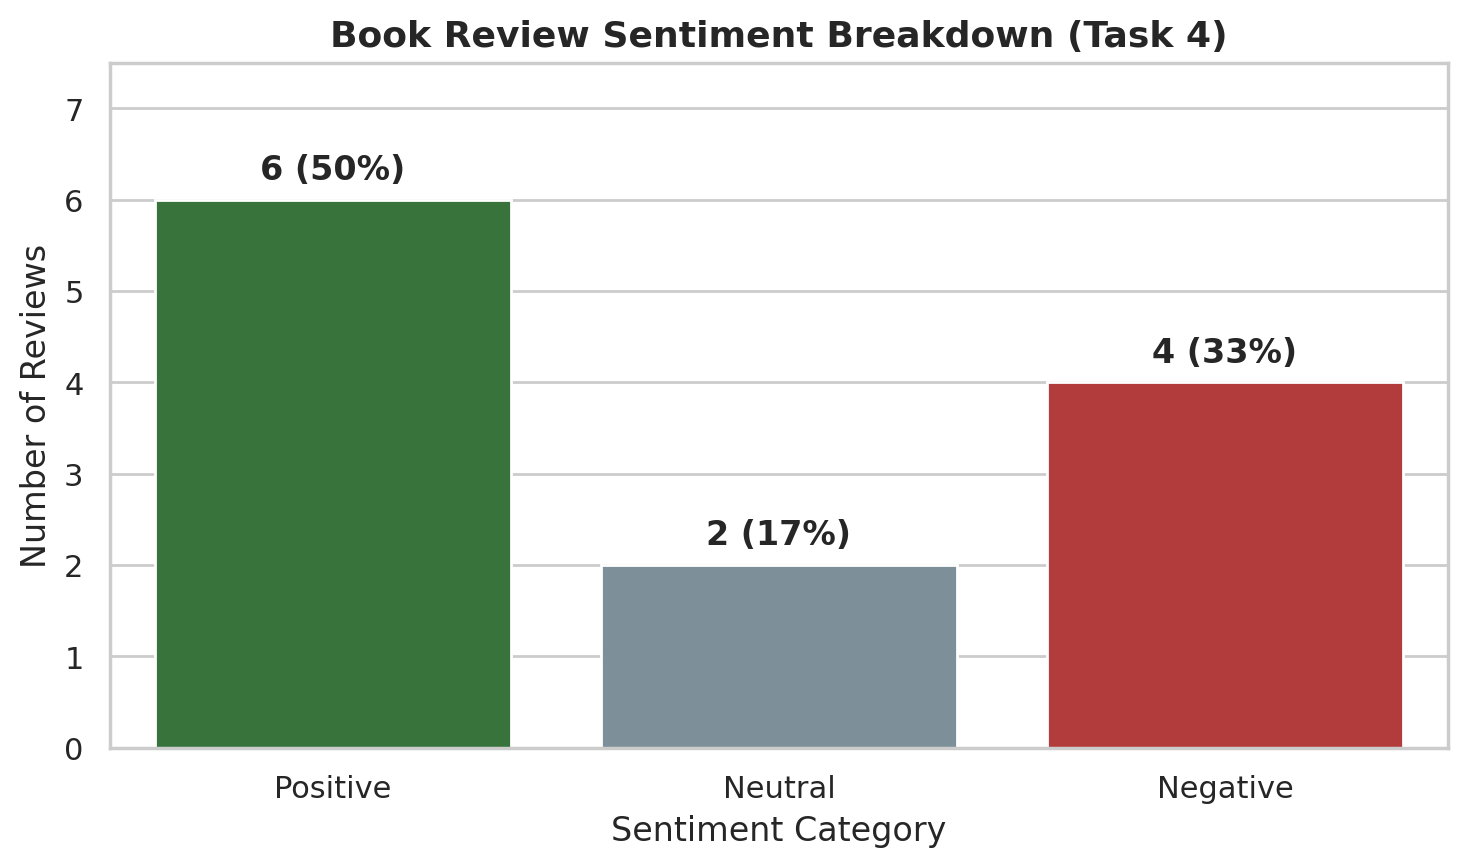


Saved sentiment CSV to: /content/outputs/task4_sentiment_results.csv
Saved sentiment chart to: /content/outputs/task4_sentiment_chart.png


In [3]:
from pathlib import Path
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

POSITIVE_WORDS = {
    "amazing", "awesome", "best", "brilliant", "captivating", "clean",
    "clear", "compelling", "easy", "engaging", "enjoyed", "excellent",
    "fantastic", "fast", "great", "happy", "helpful", "insightful",
    "love", "loved", "masterpiece", "recommend", "reliable", "smooth",
    "thoughtful", "worth",
}

NEGATIVE_WORDS = {
    "awful", "bad", "boring", "broken", "cancel", "cancelled", "charged",
    "confusing", "crashing", "delay", "delayed", "disappointed",
    "disappointing", "dull", "error", "horrible", "issue", "issues",
    "late", "overpriced", "poor", "rude", "slow", "terrible", "useless",
    "worst",
}

NEGATIONS = {
    "not", "no", "never", "hardly", "barely", "without",
    "dont", "don't", "didnt", "didn't", "wasnt", "wasn't",
}


def analyze_sentiment(text: str) -> tuple[int, str]:
    """Computes a negation-aware polarity score and sentiment label."""
    tokens = re.findall(r"[a-z']+", text.lower())
    score = 0

    for i, token in enumerate(tokens):
        negated = any(tokens[j] in NEGATIONS for j in range(max(0, i - 2), i))
        if token in POSITIVE_WORDS:
            score += -1 if negated else 1
        elif token in NEGATIVE_WORDS:
            score += 1 if negated else -1

    if score > 0:
        return score, "Positive"
    if score < 0:
        return score, "Negative"
    return 0, "Neutral"


def main() -> None:
    output_dir = Path("/content/outputs") if Path("/content").exists() else Path("outputs")
    output_dir.mkdir(parents=True, exist_ok=True)

    reviews_data = [
        ("Sapiens: A Brief History of Humankind", "Brilliant and deeply insightful read; I loved every chapter and highly recommend it."),
        ("Tipping the Velvet", "Slow pacing in the middle and frankly disappointing compared to the hype."),
        ("A Light in the Attic", "A charming, engaging collection—easy to read and great for all ages."),
        ("Soumission", "Not happy with the storyline at all; found the ending confusing and dull."),
        ("Sharp Objects", "Compelling thriller with fast pacing and a sharp, unforgettable plot."),
        ("In Her Wake", "Standard mystery novel, nothing unusual to report for the price."),
        ("The Black Maria", "Overpriced for such a short volume; I was disappointed by the print quality."),
        ("Set Me Free", "Not bad at all once the second half picks up momentum."),
        ("Behind Closed Doors", "Amazing suspense from start to finish—worth every penny!"),
        ("The Bear and the Piano", "Arrived on time in standard packaging; average story overall."),
        ("My Name Is Lucy Barton", "Terrible delivery delay and the cover arrived damaged."),
        ("The Four Agreements", "Clear, thoughtful, and helpful practical advice that I still revisit."),
    ]

    df = pd.DataFrame(reviews_data, columns=["book_title", "review_text"])
    df.insert(0, "review_id", np.arange(1, len(df) + 1))

    scored = df["review_text"].apply(analyze_sentiment)
    df["polarity_score"] = [s[0] for s in scored]
    df["sentiment"] = [s[1] for s in scored]

    print("=== TASK 4: SENTIMENT ANALYSIS SUMMARY ===")
    print(f"Total reviews analyzed: {len(df)}")
    print(f"Missing values: {int(df.isnull().sum().sum())}")
    print(f"Average polarity score: {df['polarity_score'].mean():.2f}\n")

    print("=== SENTIMENT DISTRIBUTION ===")
    dist = df["sentiment"].value_counts()
    pct = (df["sentiment"].value_counts(normalize=True) * 100).round(1)
    print(pd.DataFrame({"count": dist, "percentage": pct}).to_string())

    print("\n=== LABELED REVIEWS ===")
    print(df[["review_id", "book_title", "polarity_score", "sentiment"]].to_string(index=False))

    # Save CSV
    csv_path = output_dir / "task4_sentiment_results.csv"
    df.to_csv(csv_path, index=False)

    # Generate visual chart
    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(7.5, 4.5), dpi=200)
    order = ["Positive", "Neutral", "Negative"]
    counts = df["sentiment"].value_counts().reindex(order).fillna(0)

    sns.barplot(
        x=counts.index,
        y=counts.values,
        hue=counts.index,
        legend=False,
        palette=["#2e7d32", "#78909c", "#c62828"],
        ax=ax,
    )
    ax.set_title("Book Review Sentiment Breakdown (Task 4)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Sentiment Category")
    ax.set_ylabel("Number of Reviews")
    ax.set_ylim(0, max(counts.values) + 1.5)

    for idx, val in enumerate(counts.values):
        ax.text(
            idx,
            val + 0.15,
            f"{int(val)} ({val / len(df) * 100:.0f}%)",
            ha="center",
            va="bottom",
            fontweight="bold",
        )

    plt.tight_layout()
    chart_path = output_dir / "task4_sentiment_chart.png"
    plt.savefig(chart_path, dpi=200)
    plt.show()

    print(f"\nSaved sentiment CSV to: {csv_path.resolve()}")
    print(f"Saved sentiment chart to: {chart_path.resolve()}")


if __name__ == "__main__":
    main()